# RT-IoT2022 - Exploratory Data Analysis

The goal of this notebook is to analyze the RT-IoT2022 dataset. In particular, we want to understand:

- The size of the dataset
- The available features and their data types
- The presence of missing values or duplicates
- The distribution of normal and anomalous traffic

These results guide the choices made in the next notebooks (preprocessing, data split and evaluation metrics).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/raw/RT_IOT2022.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 123117
Number of columns: 85


In [4]:
df.head()
print(df.columns.tolist())
df.info()

['Unnamed: 0', 'id.orig_p', 'id.resp_p', 'proto', 'service', 'flow_duration', 'fwd_pkts_tot', 'bwd_pkts_tot', 'fwd_data_pkts_tot', 'bwd_data_pkts_tot', 'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec', 'down_up_ratio', 'fwd_header_size_tot', 'fwd_header_size_min', 'fwd_header_size_max', 'bwd_header_size_tot', 'bwd_header_size_min', 'bwd_header_size_max', 'flow_FIN_flag_count', 'flow_SYN_flag_count', 'flow_RST_flag_count', 'fwd_PSH_flag_count', 'bwd_PSH_flag_count', 'flow_ACK_flag_count', 'fwd_URG_flag_count', 'bwd_URG_flag_count', 'flow_CWR_flag_count', 'flow_ECE_flag_count', 'fwd_pkts_payload.min', 'fwd_pkts_payload.max', 'fwd_pkts_payload.tot', 'fwd_pkts_payload.avg', 'fwd_pkts_payload.std', 'bwd_pkts_payload.min', 'bwd_pkts_payload.max', 'bwd_pkts_payload.tot', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'flow_pkts_payload.min', 'flow_pkts_payload.max', 'flow_pkts_payload.tot', 'flow_pkts_payload.avg', 'flow_pkts_payload.std', 'fwd_iat.min', 'fwd_iat.max', 'fwd_iat.to

In [5]:
missing_value = df.isnull().sum()
print("Total missing values:", missing_value.sum())
missing_value[missing_value > 0]

Total missing values: 0


Series([], dtype: int64)

The dataset does not contain missing values, so no imputation is needed.

In [6]:
df = df.drop(columns=["Unnamed: 0"])
print("New dataset shape:", df.shape)

New dataset shape: (123117, 84)


In [7]:
duplicates = df.duplicated().sum()
print("Number of duplicated rows:", duplicates)

Number of duplicated rows: 5195


The column "Unnamed: 0" is only a row index, so it is removed. This must be done before looking for duplicates: since the index is different for every row, it would make every row look unique. After removing it, we find 5195 duplicated rows.

They are removed in the preprocessing phase, before splitting the data, so that the same flow cannot appear both in training and in test.

In [8]:
numeric_columns = df.select_dtypes(include=["number"]).columns
categorical_columns = df.select_dtypes(include=["object"]).columns

print("Number of numeric columns:", len(numeric_columns))
print("Number of categorical columns:", len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns.tolist())

print(df["Attack_type"].unique())
print("Number of traffic classes:", df["Attack_type"].nunique())

attack_counts = df["Attack_type"].value_counts()
print(attack_counts)

attack_percentages = df["Attack_type"].value_counts(normalize=True) * 100
print(attack_percentages)

Number of numeric columns: 81
Number of categorical columns: 3

Categorical columns:
['proto', 'service', 'Attack_type']
['MQTT_Publish' 'Thing_Speak' 'Wipro_bulb' 'ARP_poisioning'
 'DDOS_Slowloris' 'DOS_SYN_Hping' 'Metasploit_Brute_Force_SSH'
 'NMAP_FIN_SCAN' 'NMAP_OS_DETECTION' 'NMAP_TCP_scan' 'NMAP_UDP_SCAN'
 'NMAP_XMAS_TREE_SCAN']
Number of traffic classes: 12
Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28
Name: count, dtype: int64
Attack_type
DOS_SYN_Hping                 76.885402
Thing_Speak                    6.585606
ARP_poisioning                 6.294825
MQTT_Publish                   

The dataset has 83 input features:

- 81 numeric features (flow statistics such as duration, packet counts, bytes and timing)
- 2 categorical features: 'proto' (protocol) and 'service'

The column 'Attack_type' is the target. It contains 12 traffic classes: 3 normal classes and 9 attack classes.

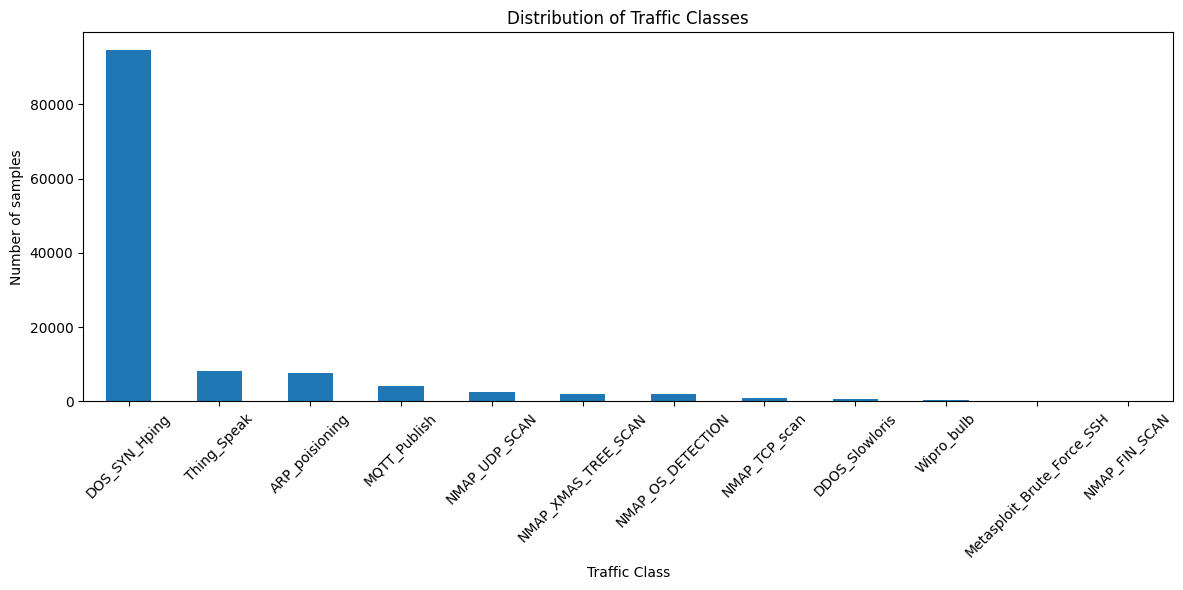

In [9]:
attack_counts.plot(kind="bar", figsize=(12,6))

plt.title("Distribution of Traffic Classes")
plt.xlabel("Traffic Class")
plt.ylabel("Number of samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
df["Attack_type"].unique()
df["Attack_type"].value_counts()

Attack_type
DOS_SYN_Hping                 94659
Thing_Speak                    8108
ARP_poisioning                 7750
MQTT_Publish                   4146
NMAP_UDP_SCAN                  2590
NMAP_XMAS_TREE_SCAN            2010
NMAP_OS_DETECTION              2000
NMAP_TCP_scan                  1002
DDOS_Slowloris                  534
Wipro_bulb                      253
Metasploit_Brute_Force_SSH       37
NMAP_FIN_SCAN                    28
Name: count, dtype: int64

In [11]:
normal_classes = ["MQTT_Publish", "Thing_Speak", "Wipro_bulb"]

df["Label"] = df["Attack_type"].apply(
    lambda x: "Normal" if x in normal_classes else "Anomaly"
)
print(df["Label"].value_counts())

label_percentages = df["Label"].value_counts(normalize = True) * 100
print(label_percentages)

Label
Anomaly    110610
Normal      12507
Name: count, dtype: int64
Label
Anomaly    89.84137
Normal     10.15863
Name: proportion, dtype: float64


For the anomaly detection, the three normal classes are:

- MQTT_Publish
- Thing_Speak
- Wipro_bulb

All other classes are considered anomalous, so the dataset is strongly unbalanced:

- Normal traffic: 12507 samples (about 10%)
- Anomalous traffic: 110610 samples (about 90%)

A single attack, DOS_SYN_Hping, represents about 77% of the whole dataset. Some classes are very small, for example NMAP_FIN_SCAN (28 samples), Metasploit_Brute_Force_SSH (37) and the normal class Wipro_bulb (253).

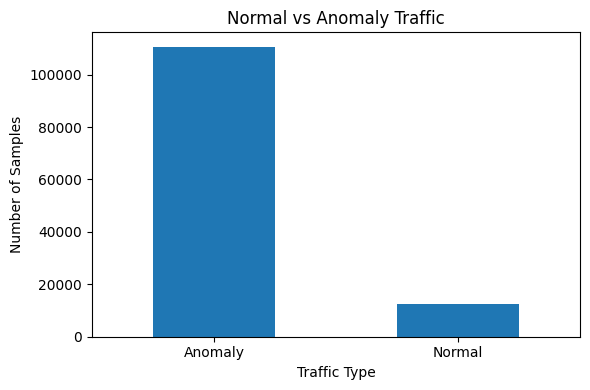

,id.orig_p,id.resp_p,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,...,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size
count,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,1.231170e+05,1.231170e+05,1.231170e+05,...,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,123117.000000,123117.000000,123117.000000
mean,34639.258738,1014.305092,3.809566,2.268826,1.909509,1.471218,0.820260,3.518063e+05,3.517620e+05,7.035683e+05,...,1.481354e+05,2.353599e+04,1.616655e+06,1.701956e+06,3.517644e+06,1.664985e+06,4.550183e+04,6118.905123,2739.776018,751.647514
std,19070.620354,5256.371994,130.005408,22.336565,33.018311,19.635196,32.293948,3.707645e+05,3.708015e+05,7.415634e+05,...,1.613007e+06,1.477935e+06,8.809396e+06,9.252337e+06,1.229508e+08,9.007064e+06,1.091361e+06,18716.313861,10018.848534,6310.183843
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,17702.000000,21.000000,0.000001,1.000000,1.000000,1.000000,0.000000,7.454354e+01,7.288927e+01,1.490871e+02,...,9.536740e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
50%,37221.000000,21.000000,0.000004,1.000000,1.000000,1.000000,0.000000,2.467238e+05,2.467238e+05,4.934475e+05,...,4.053116e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
75%,50971.000000,21.000000,0.000005,1.000000,1.000000,1.000000,0.000000,5.242880e+05,5.242880e+05,1.048576e+06,...,5.006790e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
max,65535.000000,65389.000000,21728.335578,4345.000000,10112.000000,4345.000000,10105.000000,1.048576e+06,1.048576e+06,2.097152e+06,...,4.374931e+08,4.774862e+08,3.000000e+08,3.000000e+08,2.096777e+10,3.000000e+08,1.208029e+08,65535.000000,65535.000000,65535.000000


In [12]:
label_counts = df["Label"].value_counts()
label_counts.plot(kind="bar", figsize=(6,4))

plt.title("Normal vs Anomaly Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()
df[numeric_columns].describe()

In [13]:
print("Protocol values:")
print(df["proto"].value_counts())

print("\nService values:")
print(df["service"].value_counts())

Protocol values:
proto
tcp     110427
udp      12633
icmp        57
Name: count, dtype: int64

Service values:
service
-         102861
dns         9753
mqtt        4132
http        3464
ssl         2663
ntp          121
dhcp          50
irc           43
ssh           28
radius         2
Name: count, dtype: int64


Most of the traffic uses TCP. For 'service', the value '-' means that the service could not be identified, and it is the most frequent value. 

Both columns are categorical, so they will be converted with one-hot encoding in the preprocessing phase

## Conclusions

Up to now, we can clearly see that:
-  the dataset contains 123117 samples, 83 input features and no missing values. 
- Also, after removing the index column, 5195 duplicated rows are found and must be removed before the split. 
- Normal traffic is only about 10% of the data, while the anomalous traffic is about 90% with, in particular, one attack that covers the 77% of the total data.


These observations lead to three choices for the rest of the project:

- **Anomaly detection approach:** the models are trained only on normal traffic and must recognize everything that deviates from it.
- **Evaluation metrics:** since the classes are unbalanced, accuracy alone is misleading. We use Balanced Accuracy as the main metric, together with recall and False Positive Rate.
- **Rare Classes:** classes with very few samples (for example Wipro_bulb) may be harder to model and need to be checked in the results.